In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("../data/processed/sales_analysis_ready.csv",
                 dtype={"postal_code": str},
                 parse_dates=["order_date", "ship_date"])

sns.set_theme(style="whitegrid")
print(df.shape)

(9993, 27)


In [2]:
print("Rows:", len(df))
print("Columns:", df.shape[1])
print("Orders:", df["order_id"].nunique())
print("Customers:", df["customer_id"].nunique())
print("Product names:", df["product_name"].nunique())
print("Product IDs:", df["product_id"].nunique())
print("Product keys:", df["product_key"].nunique())
print("States:", df["state"].nunique())
print("Period:", df["order_date"].min().date(), "to", df["order_date"].max().date())

ids_per_name = df.groupby("product_name")["product_id"].nunique()
print("Product names with more than one Product ID:", (ids_per_name > 1).sum())

Rows: 9993
Columns: 27
Orders: 5009
Customers: 793
Product names: 1850
Product IDs: 1862
Product keys: 1894
States: 49
Period: 2014-01-03 to 2017-12-30
Product names with more than one Product ID: 16


In [3]:
total_sales = df["sales"].sum()
total_profit = df["profit"].sum()
orders = df["order_id"].nunique()

print("Total sales:", round(total_sales, 2))
print("Total profit:", round(total_profit, 2))
print("Profit margin %:", round(total_profit / total_sales * 100, 2))
print("Average order value:", round(total_sales / orders, 2))
print("Average lines per order:", round(len(df) / orders, 2))

Total sales: 2296919.49
Total profit: 286409.08
Profit margin %: 12.47
Average order value: 458.56
Average lines per order: 2.0


                sales    profit  sales_growth_pct  profit_margin_pct
order_year                                                          
2014        483966.13  49556.03               NaN              10.24
2015        470532.51  61618.60             -2.78              13.10
2016        609205.60  81795.17             29.47              13.43
2017        733215.26  93439.27             20.36              12.74


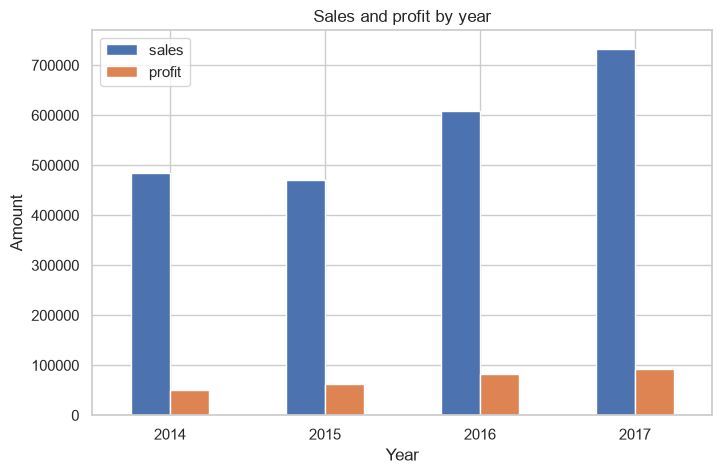

In [4]:
yearly = df.groupby("order_year")[["sales", "profit"]].sum().round(2)
yearly["sales_growth_pct"] = (yearly["sales"].pct_change() * 100).round(2)
yearly["profit_margin_pct"] = (yearly["profit"] / yearly["sales"] * 100).round(2)
print(yearly)

fig, ax = plt.subplots(figsize=(8, 5))
yearly[["sales", "profit"]].plot(kind="bar", ax=ax, rot=0)
ax.set_title("Sales and profit by year")
ax.set_xlabel("Year")
ax.set_ylabel("Amount")
plt.savefig("../images/eda_01_yearly_sales_profit.png", dpi=150, bbox_inches="tight")
plt.show()

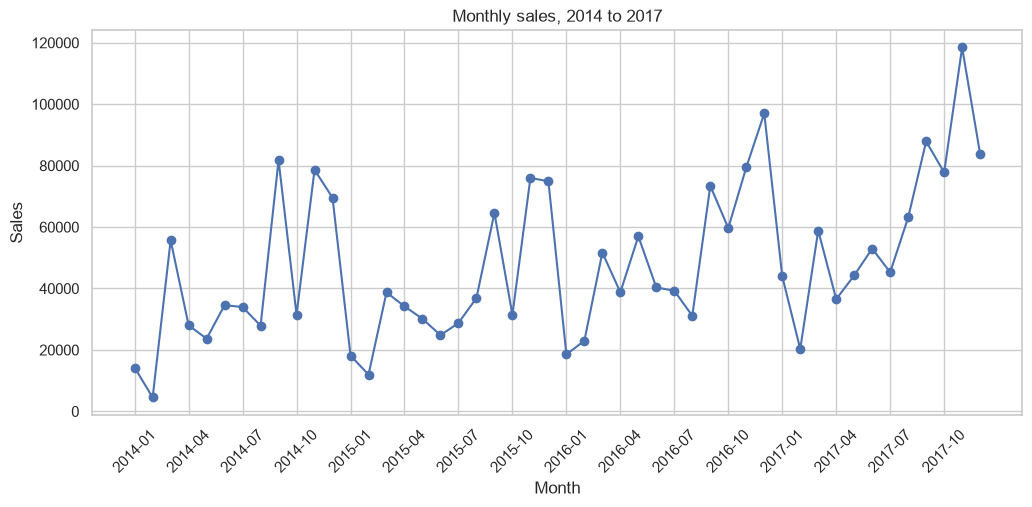

In [5]:
monthly = df.groupby("year_month")["sales"].sum().reset_index()

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(monthly["year_month"], monthly["sales"], marker="o")
ax.set_xticks(range(0, len(monthly), 3))
ax.set_xticklabels(monthly["year_month"][::3], rotation=45)
ax.set_title("Monthly sales, 2014 to 2017")
ax.set_xlabel("Month")
ax.set_ylabel("Sales")
plt.savefig("../images/eda_02_monthly_sales.png", dpi=150, bbox_inches="tight")
plt.show()

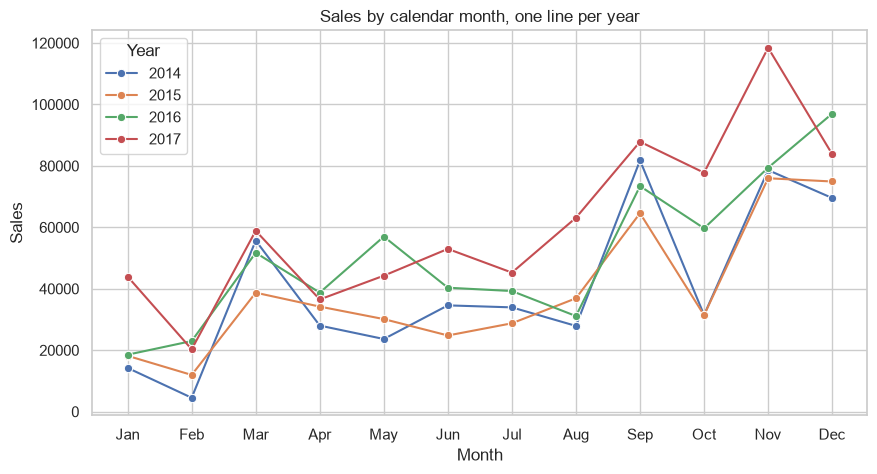

order_year   2014  2015  2016  2017
order_month                        
1             2.9   3.9   3.0   6.0
2             0.9   2.5   3.8   2.8
3            11.5   8.2   8.5   8.0
4             5.8   7.3   6.4   5.0
5             4.9   6.4   9.4   6.0
6             7.1   5.3   6.6   7.2
7             7.0   6.1   6.4   6.2
8             5.8   7.8   5.1   8.6
9            16.9  13.7  12.1  12.0
10            6.5   6.7   9.8  10.6
11           16.2  16.1  13.0  16.2
12           14.4  15.9  15.9  11.4
order_year
2014    47.5
2015    45.7
2016    41.0
2017    39.6
dtype: float64


In [6]:
month_year = df.groupby(["order_year", "order_month"])["sales"].sum().reset_index()
month_year["order_year"] = month_year["order_year"].astype(str)

fig, ax = plt.subplots(figsize=(10, 5))
sns.lineplot(data=month_year, x="order_month", y="sales", hue="order_year", marker="o", ax=ax)
ax.set_xticks(range(1, 13))
ax.set_xticklabels(["Jan", "Feb", "Mar", "Apr", "May", "Jun",
                    "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"])
ax.set_title("Sales by calendar month, one line per year")
ax.set_xlabel("Month")
ax.set_ylabel("Sales")
ax.legend(title="Year")
plt.savefig("../images/eda_03_seasonality_by_year.png", dpi=150, bbox_inches="tight")
plt.show()

share = df.groupby(["order_year", "order_month"])["sales"].sum().unstack(0)
share_pct = (share / share.sum() * 100).round(1)
print(share_pct)
print(share_pct.loc[[9, 11, 12]].sum())

                     sales     profit  profit_margin_pct
category                                                
Furniture        741718.42   18463.33               2.49
Office Supplies  719047.03  122490.80              17.04
Technology       836154.03  145454.95              17.40


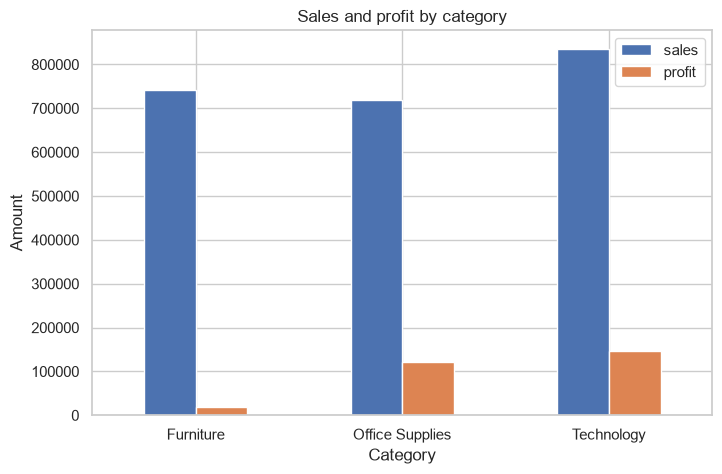

In [7]:
category = df.groupby("category")[["sales", "profit"]].sum().round(2)
category["profit_margin_pct"] = (category["profit"] / category["sales"] * 100).round(2)
print(category)

fig, ax = plt.subplots(figsize=(8, 5))
category[["sales", "profit"]].plot(kind="bar", ax=ax, rot=0)
ax.set_title("Sales and profit by category")
ax.set_xlabel("Category")
ax.set_ylabel("Amount")
plt.savefig("../images/eda_04_category.png", dpi=150, bbox_inches="tight")
plt.show()

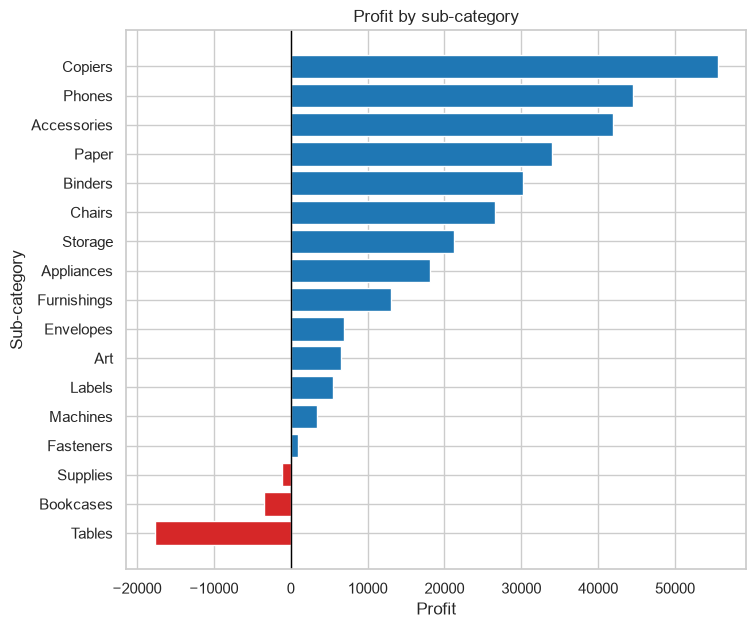

In [8]:
sub = df.groupby(["category", "sub_category"])["profit"].sum().reset_index().sort_values("profit")
colors = ["tab:red" if v < 0 else "tab:blue" for v in sub["profit"]]

fig, ax = plt.subplots(figsize=(8, 7))
ax.barh(sub["sub_category"], sub["profit"], color=colors)
ax.axvline(0, color="black", linewidth=1)
ax.set_title("Profit by sub-category")
ax.set_xlabel("Profit")
ax.set_ylabel("Sub-category")
plt.savefig("../images/eda_05_subcategory_profit.png", dpi=150, bbox_inches="tight")
plt.show()

             sales     profit  profit_margin_pct
region                                          
West     725457.82  108418.45              14.94
East     678499.87   91534.84              13.49
Central  501239.89   39706.36               7.92
South    391721.90   46749.43              11.93


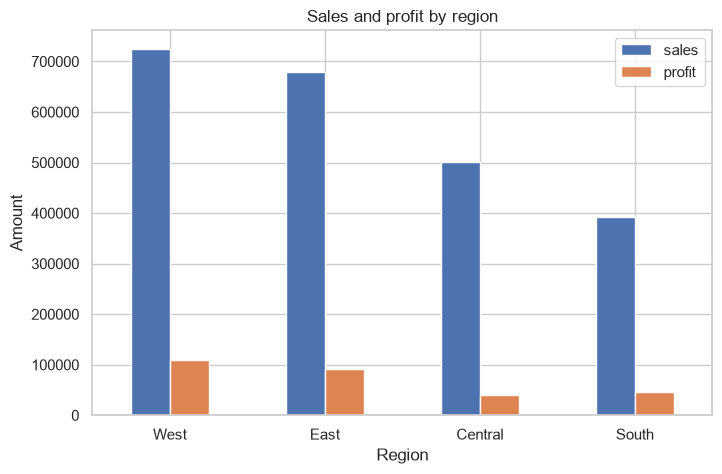

In [9]:
region = df.groupby("region")[["sales", "profit"]].sum().round(2).sort_values("sales", ascending=False)
region["profit_margin_pct"] = (region["profit"] / region["sales"] * 100).round(2)
print(region)

fig, ax = plt.subplots(figsize=(8, 5))
region[["sales", "profit"]].plot(kind="bar", ax=ax, rot=0)
ax.set_title("Sales and profit by region")
ax.set_xlabel("Region")
ax.set_ylabel("Amount")
plt.savefig("../images/eda_06_region.png", dpi=150, bbox_inches="tight")
plt.show()

                                        product_name     sales    profit
0              Canon imageCLASS 2200 Advanced Copier  61599.82  25199.93
1  Fellowes PB500 Electric Punch Plastic Comb Bin...  27453.38   7753.04
2  Cisco TelePresence System EX90 Videoconferenci...  22638.48  -1811.08
3       HON 5400 Series Task Chairs for Big and Tall  21870.58      0.00
4         GBC DocuBind TL300 Electric Binding System  19823.48   2233.51
5   GBC Ibimaster 500 Manual ProClick Binding System  19024.50    760.98
6               Hewlett Packard LaserJet 3310 Copier  18839.69   6983.88
7  HP Designjet T520 Inkjet Large Format Printer ...  18374.90   4094.98
8          GBC DocuBind P400 Electric Binding System  17965.07  -1878.17
9        High Speed Automatic Electric Letter Opener  17030.31   -262.00
Share of total sales: 10.65 %


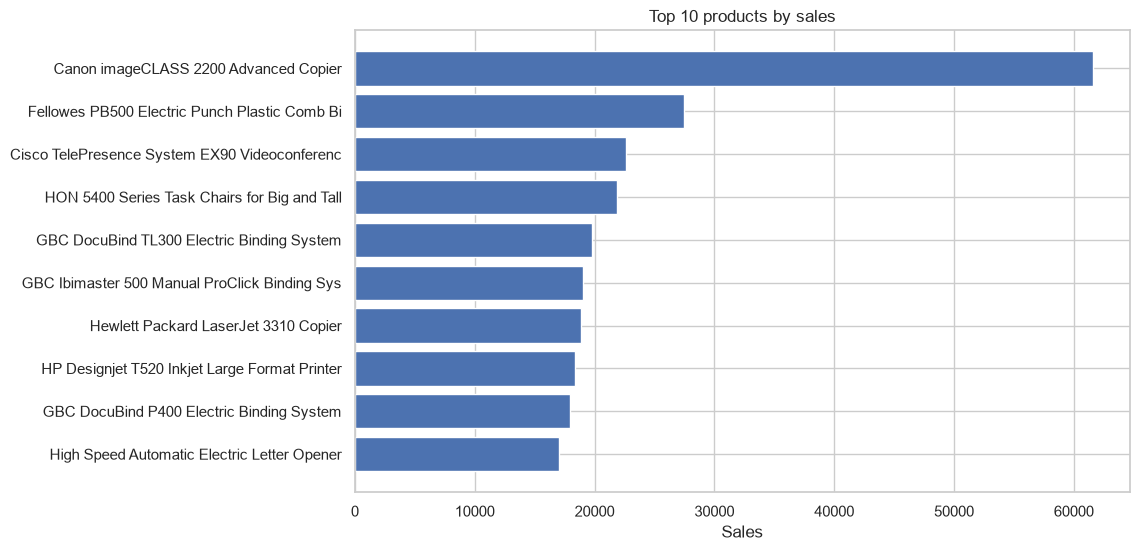

In [10]:
top_products = (df.groupby(["product_key", "product_name"])
                  .agg(sales=("sales", "sum"), profit=("profit", "sum"))
                  .sort_values("sales", ascending=False)
                  .head(10)
                  .reset_index())
print(top_products[["product_name", "sales", "profit"]].round(2))
print("Share of total sales:", round(top_products["sales"].sum() / df["sales"].sum() * 100, 2), "%")

plot_data = top_products.sort_values("sales")
fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(plot_data["product_name"].str.slice(0, 45), plot_data["sales"])
ax.set_title("Top 10 products by sales")
ax.set_xlabel("Sales")
plt.savefig("../images/eda_07_top_products.png", dpi=150, bbox_inches="tight")
plt.show()

    discount  lines       sales     profit  profit_margin_pct
0       0.00   4798  1087908.47  320987.60              29.51
1       0.10     94    54369.35    9029.18              16.61
2       0.15     52    27558.52    1418.99               5.15
3       0.20   3657   764594.37   90337.31              11.82
4       0.30    226   102945.28  -10357.22             -10.06
5       0.32     27    14493.46   -2391.14             -16.50
6       0.40    206   116417.78  -23057.05             -19.81
7       0.45     11     5484.97   -2493.11             -45.45
8       0.50     66    58918.54  -20506.43             -34.80
9       0.60    138     6644.70   -5944.66             -89.46
10      0.70    418    40620.28  -40075.36             -98.66
11      0.80    300    16963.76  -30539.04            -180.03


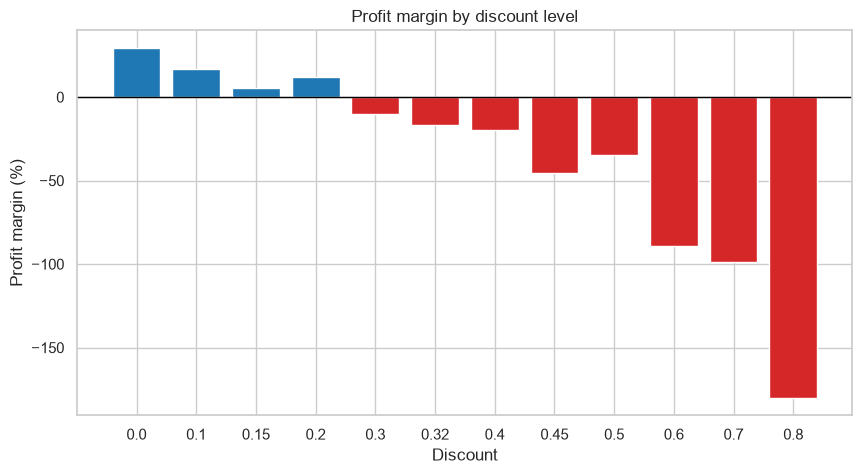

In [11]:
disc = (df.groupby("discount")
          .agg(lines=("row_id", "count"), sales=("sales", "sum"), profit=("profit", "sum"))
          .reset_index())
disc["profit_margin_pct"] = (disc["profit"] / disc["sales"] * 100).round(2)
print(disc.round(2))

colors = ["tab:red" if v < 0 else "tab:blue" for v in disc["profit_margin_pct"]]
fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(disc["discount"].astype(str), disc["profit_margin_pct"], color=colors)
ax.axhline(0, color="black", linewidth=1)
ax.set_title("Profit margin by discount level")
ax.set_xlabel("Discount")
ax.set_ylabel("Profit margin (%)")
plt.savefig("../images/eda_08_discount_margin.png", dpi=150, bbox_inches="tight")
plt.show()

  customer_id       customer_name  orders     sales   profit
0    SM-20320         Sean Miller       5  25043.05 -1980.74
1    TC-20980        Tamara Chand       5  19052.22  8981.32
2    RB-19360        Raymond Buch       6  15117.34  6976.10
3    TA-21385        Tom Ashbrook       4  14595.62  4703.79
4    AB-10105       Adrian Barton      10  14473.57  5444.81
5    KL-16645        Ken Lonsdale      12  14175.23   806.86
6    SC-20095        Sanjit Chand       9  14142.33  5757.41
7    HL-15040        Hunter Lopez       6  12873.30  5622.43
8    SE-20110        Sanjit Engle      11  12209.44  2650.68
9    CC-12370  Christopher Conant       5  12129.07  2177.05


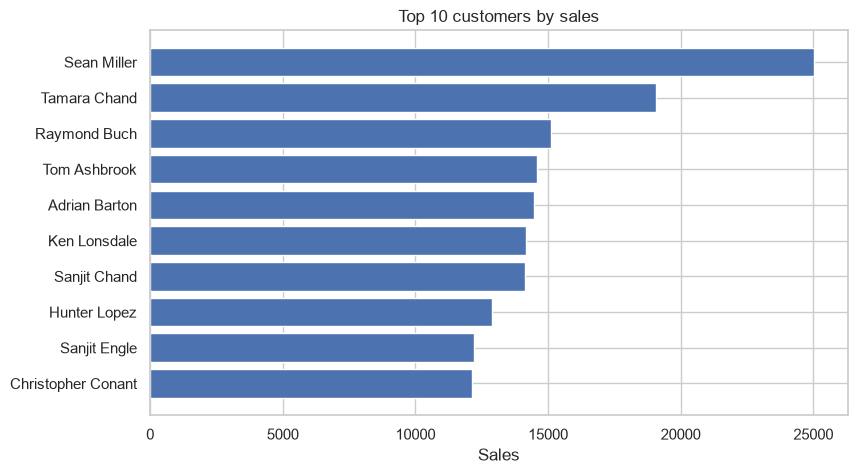

In [12]:
cust = (df.groupby(["customer_id", "customer_name"])
          .agg(orders=("order_id", "nunique"), sales=("sales", "sum"), profit=("profit", "sum"))
          .sort_values("sales", ascending=False)
          .head(10)
          .reset_index())
print(cust.round(2))

plot_c = cust.sort_values("sales")
fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(plot_c["customer_name"], plot_c["sales"])
ax.set_title("Top 10 customers by sales")
ax.set_xlabel("Sales")
plt.savefig("../images/eda_09_top_customers.png", dpi=150, bbox_inches="tight")
plt.show()

             customers  orders       sales     profit  profit_margin_pct  \
segment                                                                    
Consumer           409    2586  1161401.34  134119.21              11.55   
Corporate          236    1514   706146.37   91979.13              13.03   
Home Office        148     909   429371.78   60310.74              14.05   

             sales_per_customer  
segment                          
Consumer                2839.61  
Corporate               2992.15  
Home Office             2901.16  


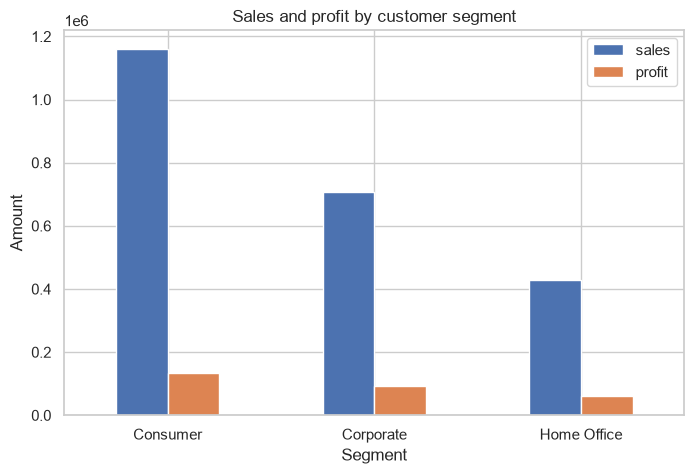

In [13]:
seg = (df.groupby("segment")
         .agg(customers=("customer_id", "nunique"), orders=("order_id", "nunique"),
              sales=("sales", "sum"), profit=("profit", "sum")))
seg["profit_margin_pct"] = (seg["profit"] / seg["sales"] * 100).round(2)
seg["sales_per_customer"] = (seg["sales"] / seg["customers"]).round(2)
print(seg.round(2))

fig, ax = plt.subplots(figsize=(8, 5))
seg[["sales", "profit"]].plot(kind="bar", ax=ax, rot=0)
ax.set_title("Sales and profit by customer segment")
ax.set_xlabel("Segment")
ax.set_ylabel("Amount")
plt.savefig("../images/eda_10_segment.png", dpi=150, bbox_inches="tight")
plt.show()

In [14]:
furn = df[df["category"] == "Furniture"]
print("Furniture share of sales %:", round(furn["sales"].sum() / df["sales"].sum() * 100, 2))
print("Furniture share of profit %:", round(furn["profit"].sum() / df["profit"].sum() * 100, 2))

high_disc = df[df["discount"] >= 0.30]
print("Lines with discount >= 0.30:", len(high_disc), round(len(high_disc) / len(df) * 100, 2), "%")
print("Their sales:", round(high_disc["sales"].sum(), 2), "| their profit:", round(high_disc["profit"].sum(), 2))
print("Profit on lines with no discount:", round(df.loc[df["discount"] == 0, "profit"].sum(), 2))

print("\nAverage discount by region")
print(df.groupby("region")["discount"].mean().round(3))
print("\n% of lines with discount >= 0.30, by region")
print((df["discount"] >= 0.30).groupby(df["region"]).mean().mul(100).round(1))
print("\nAverage discount by year")
print(df.groupby("order_year")["discount"].mean().round(3))

Furniture share of sales %: 32.29
Furniture share of profit %: 6.45
Lines with discount >= 0.30: 1392 13.93 %
Their sales: 362488.78 | their profit: -135364.0
Profit on lines with no discount: 320987.6

Average discount by region
region
Central    0.240
East       0.145
South      0.147
West       0.109
Name: discount, dtype: float64

% of lines with discount >= 0.30, by region
region
Central    27.7
East       16.2
South      10.6
West        3.7
Name: discount, dtype: float64

Average discount by year
order_year
2014    0.158
2015    0.156
2016    0.155
2017    0.156
Name: discount, dtype: float64


## Key insights from EDA

1. **Furniture sells a lot but earns little.** Furniture is 32.3% of all sales (741,718 of 2,296,919) but only 6.5% of profit (18,463 of 286,409). Its profit margin is 2.49%, against about 17% for Office Supplies and Technology. Inside Furniture, Tables (-17,725) and Bookcases (-3,472) lose money, while Chairs (+26,602) and Furnishings (+13,059) make profit. Management should check pricing and discounts on Tables and Bookcases before pushing more Furniture sales.

2. **Big discounts go together with losses.** Lines with no discount (48% of all lines) earned 320,988 profit, which is more than the whole company's profit (286,409). Lines with a discount of 30% or more are 13.9% of lines and 15.8% of sales (about 362,489), but they lost about 135,364. The profit margin is 29.51% with no discount, 11.82% at 20%, and negative at every discount level from 30% up. This shows a strong link, but it does not yet prove that discounts cause the losses. We will test it in the statistics step. A review of discounts of 30% and above looks worthwhile.

3. **September, November and December are the peak months in every year.** In each of the four years, these three months were the top three, and together they made 39.6% to 47.5% of that year's sales. Their share fell from 47.5% (2014) to 39.6% (2017), so other months are also growing. Stock, delivery capacity and promotions should be planned early for September to December. January and February are the weakest months, and could be tested with special offers.

4. **Sales grew after 2015, but the profit margin stopped improving.** Sales fell 2.78% in 2015, then grew 29.47% in 2016 and 20.36% in 2017. Profit rose every year (49,556 in 2014 to 93,439 in 2017). The profit margin rose from 10.24% (2014) to 13.43% (2016), then slipped to 12.74% (2017). The average discount was almost the same every year (about 0.16), so a change in the discount level is not an obvious reason. The product mix needs checking.

5. **The Central region sells well but earns little.** Central sales (501,240) are higher than South (391,722), but Central profit (39,706) is lower than South (46,749). Central's margin is 7.92%, against 11.93% to 14.94% in the other regions. Central also gives the biggest discounts: an average discount of 0.24 (others 0.11 to 0.15), and 27.7% of its lines have a discount of 30% or more (West: 3.7%). Those heavily discounted Central lines lost about 52,392. This suggests that Central's discount practice is worth reviewing, but we still need to test it properly.

6. **The best-selling products are not always the most profitable.** The top 10 products make 10.65% of all sales. The Canon imageCLASS 2200 Advanced Copier is number 1 (sales 61,600, profit 25,200). But the Cisco TelePresence System EX90 is number 3 by sales and lost 1,811, and the HON 5400 Series Task Chairs (number 4) made 0.00 profit. Overall, 304 of the 1,894 product entries have a negative total profit. Products should be ranked by profit as well as by sales.

7. **The biggest customers by sales are not always profitable.** The top 10 customers make only 6.7% of total sales, so the business does not depend on a few customers. But the number 1 customer by sales (Sean Miller, 25,043) has a loss of 1,981. Customers should be ranked by profit as well as by sales.

8. **Customers come back often, but spending is uneven.** Only 12 of 793 customers ordered once, and 535 ordered 4 to 8 times. The average customer spends 2,896.49, but only 294 customers (37%) spend more than that. This means a smaller group of high spenders pulls the average up. It would help to study what these high spenders have in common.